In [1]:
# Cell 1: Setup and Imports
!pip install -q xgboost scikit-learn pandas jproperties

import os
import json
import time
import pickle
import logging
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
log = logging.getLogger("SolarTrain")

print(f"XGBoost version: {xgb.__version__}")

XGBoost version: 3.4.1


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("juanschafle/solarplant-power-generation-monitoring-2023-2025")

print("Path to dataset files:", path)

100%|██████████| 64.3k/64.3k [00:00<00:00, 12.3MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/juanschafle/solarplant-power-generation-monitoring-2023-2025/versions/1


In [3]:
# Cell 2: Configuration and Evaluation Metrics

CONFIG = {
    "project": "solar_power_project",
    "label_col": "power_generation_kw",
    "eval_metric": "rmse",
    "hyper_params": {
        "max_depth": 6,
        "learning_rate": 0.1,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "n_estimators": 100,
        "objective": "reg:squarederror"
    }
}

class Metric:
    def __init__(self, fn, higher_is_better):
        self.fn, self.higher_is_better = fn, higher_is_better

    def __call__(self, y_true, y_pred):
        return round(float(self.fn(y_true, y_pred)), 6)

METRICS = {
    "rmse": Metric(lambda y, p: mean_squared_error(y, p) ** 0.5, higher_is_better=False),
    "mae": Metric(mean_absolute_error, higher_is_better=False),
    "r2": Metric(r2_score, higher_is_better=True),
}

metric = METRICS[CONFIG["eval_metric"]]

In [4]:
# Cell 3: Data Loading, Feature Engineering, and Train/Val/Test Split

# DATA_FILE = "/content/solar_plant_generation_dataset.csv"
DATA_FILE = os.path.join(path,"solar_plant_generation_dataset.csv")

if not os.path.exists(DATA_FILE):
    raise FileNotFoundError(f"Dataset not found at: {DATA_FILE}. Please upload it to your Colab environment.")

log.info("Loading dataset...")
df = pd.read_csv(DATA_FILE)

# 1. Timestamp Feature Engineering for Solar Power Predictive Power
if "timestamp" in df.columns:
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df["hour"] = df["timestamp"].dt.hour                   # Diurnal sun cycle
    df["month"] = df["timestamp"].dt.month                 # Seasonality
    df["dayofyear"] = df["timestamp"].dt.dayofyear         # Day of year progression
    df["dayofweek"] = df["timestamp"].dt.dayofweek         # Day of week pattern
    df = df.drop(columns=["timestamp"])                    # Drop raw timestamp string
    log.info("Extracted time features: hour, month, dayofyear, dayofweek")

label_col = CONFIG["label_col"]
if label_col not in df.columns:
    raise ValueError(f"Target column '{label_col}' not found in dataset columns: {list(df.columns)}")

# Separate features (X) and target labels (y)
X = df.drop(columns=[label_col])
y = df[label_col]

# 2. Split dataset: 70% Train, 15% Validation, 15% Test
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.15, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1765, random_state=42) # roughly 70/15/15 split

log.info(f"Dataset split completed — Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")

In [5]:
# Cell 4: Train the XGBoost Regressor

model_path = "solar_xgboost_model.json"
params = CONFIG["hyper_params"]

log.info("Training XGBoost Regressor...")
model = xgb.XGBRegressor(**params)
model.fit(X_train, y_train, verbose=True)

# Save model artifact
model.save_model(model_path)
log.info(f"Model successfully trained and saved to {model_path}")

In [6]:
# Cell 5: Evaluate Model on Validation and Test Splits

def evaluate_split(model_path, X_data, y_true, split_name):
    model = xgb.XGBRegressor()
    model.load_model(model_path)

    y_pred = model.predict(X_data)

    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    print(f"--- {split_name} Set Evaluation ---")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAE:  {mae:.4f}")
    print(f"R2:   {r2:.4f}\n")

evaluate_split(model_path, X_val, y_val, "Validation")
evaluate_split(model_path, X_test, y_test, "Test")

--- Validation Set Evaluation ---
RMSE: 7.6183
MAE:  3.8485
R2:   0.9791

--- Test Set Evaluation ---
RMSE: 7.2545
MAE:  3.6609
R2:   0.9792



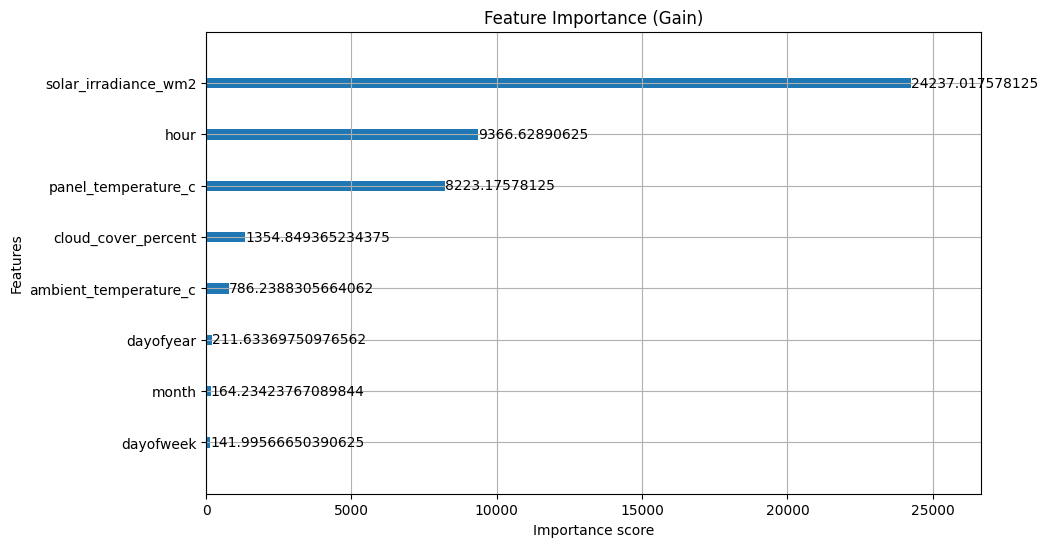

In [7]:
# Cell 6: Plot Feature Importance
import matplotlib.pyplot as plt

# Load model and ensure feature names match
model = xgb.XGBRegressor()
model.load_model("solar_xgboost_model.json")

# Plot feature importance (using 'weight' or 'gain')
plt.figure(figsize=(10, 6))
xgb.plot_importance(model, importance_type="gain", ax=plt.gca(), title="Feature Importance (Gain)")
plt.show()

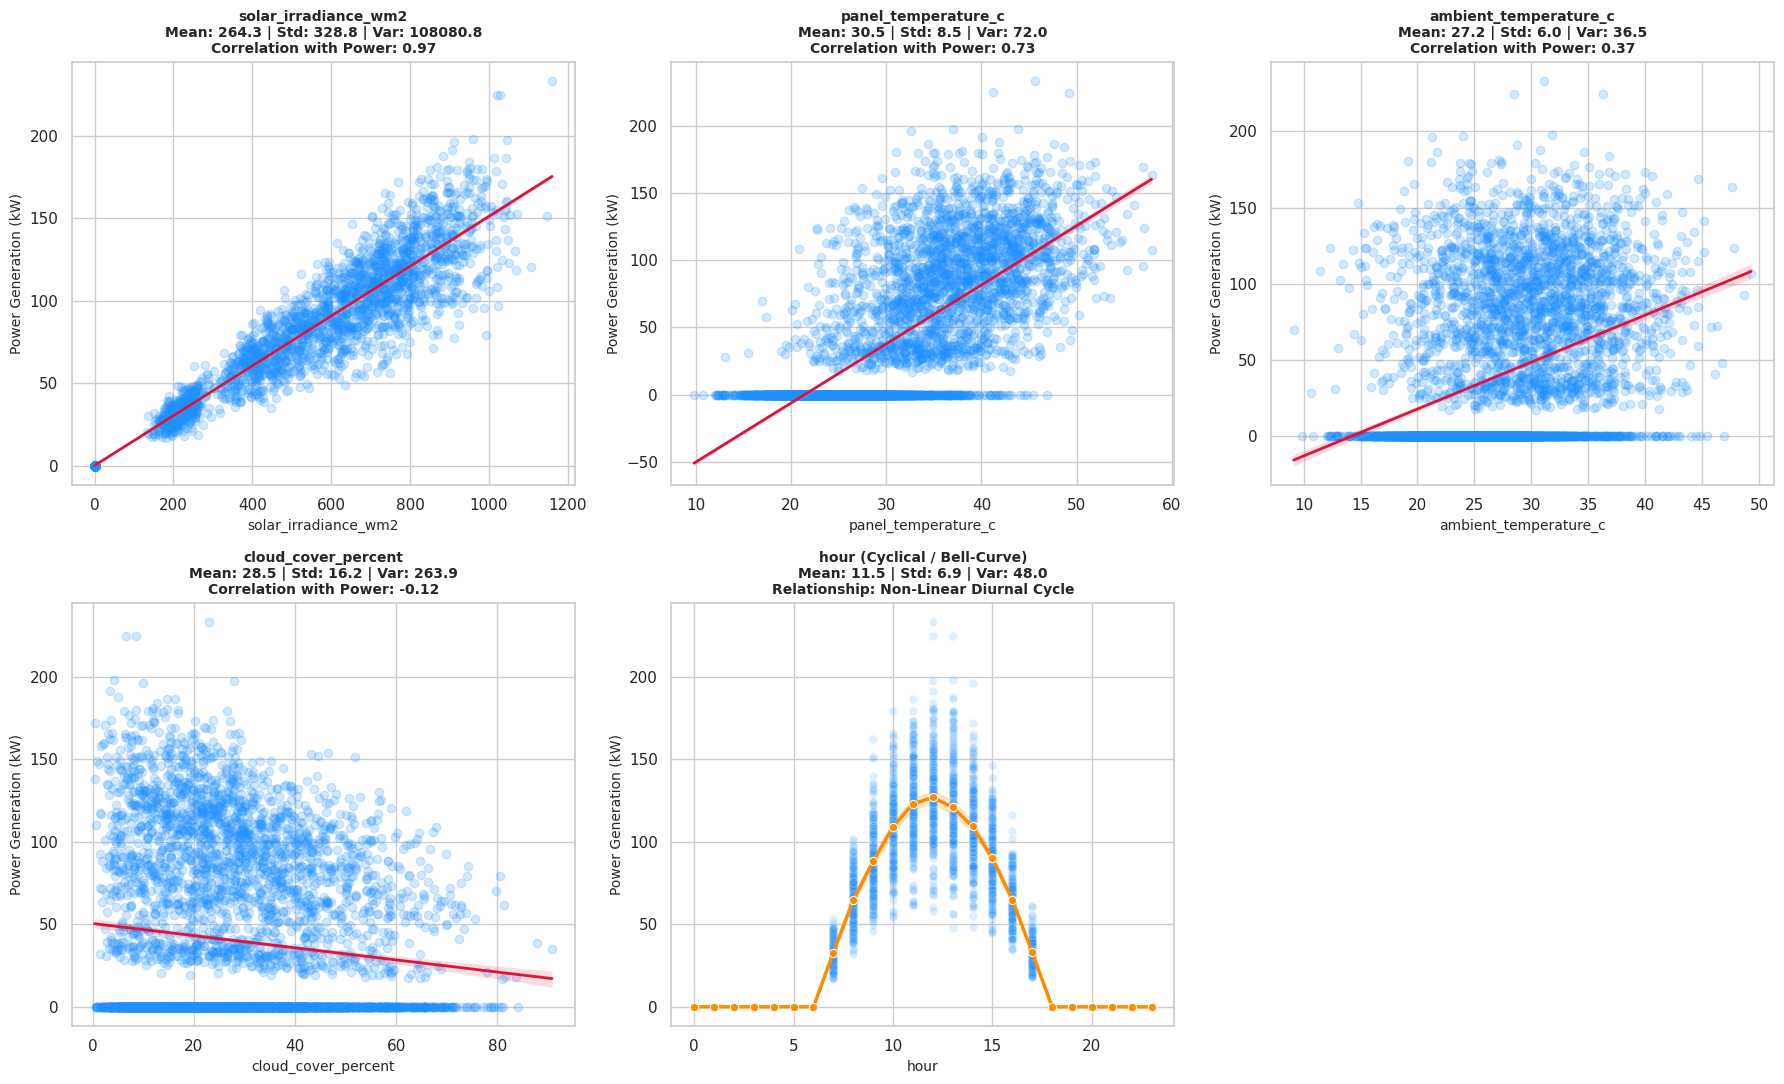

In [60]:
import seaborn as sns

if 'plot_df' not in locals():
    plot_df = X.copy()
    plot_df[CONFIG["label_col"]] = y

sns.set_theme(style="whitegrid")

features_to_plot = [
    "solar_irradiance_wm2",
    "panel_temperature_c",
    "ambient_temperature_c",
    "cloud_cover_percent",
    "hour"
]

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 11))
axes = axes.flatten()

for i, feature in enumerate(features_to_plot):
    if feature in plot_df.columns:
        feat_mean = plot_df[feature].mean()
        feat_std = plot_df[feature].std()
        feat_var = plot_df[feature].var()
        corr = plot_df[feature].corr(plot_df[CONFIG["label_col"]])

        # Special handling for 'hour' because it is a non-linear bell curve
        if feature == "hour":
            # Plot hourly mean power trend with a confidence/std band
            sns.lineplot(
                data=plot_df,
                x="hour",
                y=CONFIG["label_col"],
                ax=axes[i],
                color="darkorange",
                linewidth=2.5,
                marker="o"
            )
            # Add scatter background for hourly distribution
            sns.scatterplot(
                data=plot_df,
                x="hour",
                y=CONFIG["label_col"],
                ax=axes[i],
                alpha=0.15,
                color="dodgerblue",
                legend=False
            )
        else:
            # Standard scatter + linear regression line for weather features
            sns.regplot(
                data=plot_df,
                x=feature,
                y=CONFIG["label_col"],
                ax=axes[i],
                scatter_kws={'alpha': 0.2, 'color': 'dodgerblue'},
                line_kws={'color': 'crimson', 'linewidth': 2}
            )

        # Add metrics into the header title
        if feature == "hour":
            title_text = (
                f"{feature} (Cyclical / Bell-Curve)\n"
                f"Mean: {feat_mean:.1f} | Std: {feat_std:.1f} | Var: {feat_var:.1f}\n"
                f"Relationship: Non-Linear Diurnal Cycle"
            )
        else:
            title_text = (
                f"{feature}\n"
                f"Mean: {feat_mean:.1f} | Std: {feat_std:.1f} | Var: {feat_var:.1f}\n"
                f"Correlation with Power: {corr:.2f}"
            )
        axes[i].set_title(title_text, fontsize=10, fontweight="bold")
        axes[i].set_xlabel(feature, fontsize=10)
        axes[i].set_ylabel("Power Generation (kW)", fontsize=10)

# Hide the extra empty subplot slot
if len(features_to_plot) < len(axes):
    fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

In [8]:
# Check performance specifically during high-generation periods (> 100 kW)
mask = y_test > 100
peak_y_true = y_test[mask]
peak_y_pred = model.predict(X_test[mask])

peak_rmse = mean_squared_error(peak_y_true, peak_y_pred) ** 0.5
peak_mae = mean_absolute_error(peak_y_true, peak_y_pred)
print(f"Peak Hours ( > 100 kW ) - RMSE: {peak_rmse:.4f}, MAE: {peak_mae:.4f}")

Peak Hours ( > 100 kW ) - RMSE: 13.9472, MAE: 10.3613


In [9]:
from sklearn.linear_model import LinearRegression

# We can train a quick linear model to predict panel temperature
# based on ambient temperature and solar irradiance from our dataset
temp_X = df[['ambient_temperature_c', 'solar_irradiance_wm2']]
temp_y = df['panel_temperature_c']

panel_temp_model = LinearRegression()
panel_temp_model.fit(temp_X, temp_y)

# Print the formula learned from your specific data
print("Learned Panel Temperature Formula:")
print(f"Panel Temp = {panel_temp_model.intercept_:.2f} "
      f"+ ({panel_temp_model.coef_[0]:.3f} * Ambient Temp) "
      f"+ ({panel_temp_model.coef_[1]:.5f} * Solar Irradiance)")

Learned Panel Temperature Formula:
Panel Temp = -0.00 + (1.000 * Ambient Temp) + (0.01250 * Solar Irradiance)


In [10]:
!pip install -q requests

import requests

def predict_solar_power_from_api(latitude, longitude, model_path="solar_xgboost_model.json"):
    # 1. Fetch forecast data from Open-Meteo API
    url = (
        f"https://api.open-meteo.com/v1/forecast?"
        f"latitude={latitude}&longitude={longitude}&"
        f"hourly=temperature_2m,cloud_cover,shortwave_radiation"
    )

    response = requests.get(url)
    if response.status_code != 200:
        raise Exception(f"Failed to fetch weather data: {response.text}")

    data = response.json()
    hourly = data["hourly"]

    # 2. Build raw DataFrame from API response
    df_api = pd.DataFrame({
        "timestamp": hourly["time"],
        "solar_irradiance_wm2": hourly["shortwave_radiation"],
        "ambient_temperature_c": hourly["temperature_2m"],
        "cloud_cover_percent": hourly["cloud_cover"]
    })

    # 3. Estimate Panel Temperature using our data-driven formula
    api_temp_features = df_api[['ambient_temperature_c', 'solar_irradiance_wm2']]
    df_api['panel_temperature_c'] = panel_temp_model.predict(api_temp_features)

    # 4. Apply Timestamp Feature Engineering
    df_api["timestamp"] = pd.to_datetime(df_api["timestamp"])
    df_api["hour"] = df_api["timestamp"].dt.hour
    df_api["month"] = df_api["timestamp"].dt.month
    df_api["dayofyear"] = df_api["timestamp"].dt.dayofyear
    df_api["dayofweek"] = df_api["timestamp"].dt.dayofweek

    # Drop raw timestamp string and align columns to training data layout
    features_df = df_api.drop(columns=["timestamp"])
    features_df = features_df[X_train.columns]

    # 5. Load model and predict power generation
    model = xgb.XGBRegressor()
    model.load_model(model_path)

    df_api["predicted_power_kw"] = model.predict(features_df)
    df_api["predicted_power_kw"] = df_api["predicted_power_kw"].clip(lower=0.0)

    return df_api

# Run the updated prediction and include cloud cover in the display
forecast_df = predict_solar_power_from_api(43.651070, -79.347015)
print(forecast_df[
    ["timestamp",
     "solar_irradiance_wm2",
     "cloud_cover_percent",
     "ambient_temperature_c",
     "panel_temperature_c",
     "predicted_power_kw"
     ]
    ].head(24).to_string(index=False))

          timestamp  solar_irradiance_wm2  cloud_cover_percent  ambient_temperature_c  panel_temperature_c  predicted_power_kw
2026-11-03 00:00:00                   0.0                  100                   12.0            11.999814            0.001793
2026-11-03 01:00:00                   0.0                  100                   13.1            13.099828            0.022294
2026-11-03 02:00:00                   0.0                  100                   13.3            13.299831            0.022294
2026-11-03 03:00:00                   0.0                  100                   13.0            12.999827            0.022294
2026-11-03 04:00:00                   0.0                  100                   13.1            13.099828            0.022294
2026-11-03 05:00:00                   0.0                  100                   12.4            12.399819            0.001793
2026-11-03 06:00:00                   0.0                  100                   11.6            11.599809     